<a href="https://colab.research.google.com/github/Alifdaud/Analisis-Distribusi-Pasien-pada-Healthcare-Dataset/blob/main/Tugas2_LDA_vs_BERTopic_20Newsgroups_dengan_Gambar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 2 — Implementasi Program & Evaluasi Komparatif LDA vs BERTopic
## Dataset: 20 Newsgroups (file ZIP/CSV yang diunggah)

Notebook ini dibuat mengikuti format output contoh: grafik PNG, visualisasi interaktif HTML, dan tabel CSV. Dataset yang digunakan adalah `test_20newsgroups.csv.zip`, dengan kolom `documents`, `labels`, dan `label_names`.

**Output otomatis:** `fig_lda_k_scan.png`, `bertopic_barchart_auto.html`, `fig_perbandingan_cv.png`, `bertopic_hierarchy_auto.html`, `bertopic_intertopic_distance_auto.html`, `hasil_evaluasi.csv`, `lda_k_scan.csv`, `sensitivitas_min_cluster_size.csv`, `kestabilan_seed.csv`, serta salinan dataset yang dianalisis.

## 1. Instalasi pustaka

In [ ]:
!pip -q install pandas numpy matplotlib scikit-learn gensim nltk bertopic sentence-transformers umap-learn hdbscan plotly kaleido

## 2. Upload dataset ZIP atau CSV

In [ ]:
from google.colab import files
uploaded = files.upload()
if not uploaded:
    raise RuntimeError("Silakan upload file dataset ZIP atau CSV.")
uploaded_name = next(iter(uploaded))
print("File:", uploaded_name)

Saving test_20newsgroups.csv.zip to test_20newsgroups.csv.zip
File: test_20newsgroups.csv.zip


## 3. Ekstraksi, pembacaan, dan pemeriksaan dataset

In [ ]:
import os, glob, zipfile, shutil
import pandas as pd
from IPython.display import display

WORKDIR = "/content/hasil_topic_modeling"
os.makedirs(WORKDIR, exist_ok=True)

if uploaded_name.lower().endswith(".zip"):
    extract_dir = os.path.join(WORKDIR, "dataset")
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(uploaded_name, "r") as z:
        z.extractall(extract_dir)
    csv_files = glob.glob(os.path.join(extract_dir, "**", "*.csv"), recursive=True)
    if not csv_files:
        raise FileNotFoundError("Tidak ditemukan CSV di dalam ZIP.")
    csv_path = csv_files[0]
elif uploaded_name.lower().endswith(".csv"):
    csv_path = uploaded_name
else:
    raise ValueError("Format harus ZIP atau CSV.")

try:
    df = pd.read_csv(csv_path)
except UnicodeDecodeError:
    df = pd.read_csv(csv_path, encoding="latin-1")

print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())
display(df.head(3))

# Kolom teks utama dataset Anda adalah 'documents'.
TEXT_COL = "documents" if "documents" in df.columns else None
if TEXT_COL is None:
    candidates = ["text", "content", "article", "review", "message", "news"]
    TEXT_COL = next((c for c in candidates if c in df.columns), None)
if TEXT_COL is None:
    object_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
    if not object_cols:
        raise ValueError("Kolom teks tidak ditemukan.")
    TEXT_COL = max(object_cols, key=lambda c: df[c].fillna("").astype(str).str.len().mean())

print("Kolom teks:", TEXT_COL)

Ukuran dataset: (7048, 3)
Kolom: ['documents', 'labels', 'label_names']


,documents,labels,label_names
0,I am a little confused on all of the models of...,7,rec.autos
1,I'm not familiar at all with the format of the...,5,comp.windows.x
2,"In a word, yes.",0,alt.atheism


Kolom teks: documents


## 4. Preprocessing dan pembersihan corpus

In [ ]:
import re, nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# 20 Newsgroups merupakan korpus berbahasa Inggris.
stop_words = set(stopwords.words("english")) | set(ENGLISH_STOP_WORDS)

data = df[[TEXT_COL]].copy()
data[TEXT_COL] = data[TEXT_COL].fillna("").astype(str)
data = data[data[TEXT_COL].str.strip().ne("")]
data = data.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

data["clean_text"] = data[TEXT_COL].apply(clean_text)
data["tokens"] = data["clean_text"].apply(
    lambda s: [w for w in s.split() if w not in stop_words and len(w) > 2]
)
data = data[data["tokens"].map(len) >= 3].reset_index(drop=True)
data["processed_text"] = data["tokens"].apply(lambda x: " ".join(x))

print("Dokumen setelah preprocessing:", len(data))
if len(data) < 300:
    raise ValueError("Jumlah dokumen kurang dari 300, tidak memenuhi ketentuan tugas.")
display(data[["clean_text", "processed_text"]].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Dokumen setelah preprocessing: 6978


,clean_text,processed_text
0,i am a little confused on all of the models of...,little confused models bonnevilles heard lse s...
1,i m not familiar at all with the format of the...,familiar format face thingies seeing folks hea...
2,they were attacking the iraqis to drive them o...,attacking iraqis drive kuwait country citizens...
3,i ve just spent two solid months arguing that ...,spent solid months arguing thing objective mor...
4,elisabeth let s set the record straight for th...,elisabeth let set record straight nth time rea...


## 5. Model LDA — pencarian jumlah topik optimal (K)

K=3: Cv=0.5639
K=4: Cv=0.5565
K=5: Cv=0.4917
K=6: Cv=0.5222
K=7: Cv=0.5053
K=8: Cv=0.5140
K=9: Cv=0.5107
K=10: Cv=0.4608


,K,coherence_cv
0,3,0.563919
1,4,0.556483
2,5,0.491703
3,6,0.522246
4,7,0.505281
5,8,0.514010
6,9,0.510650
7,10,0.460845


K terbaik berdasarkan Cv: 3


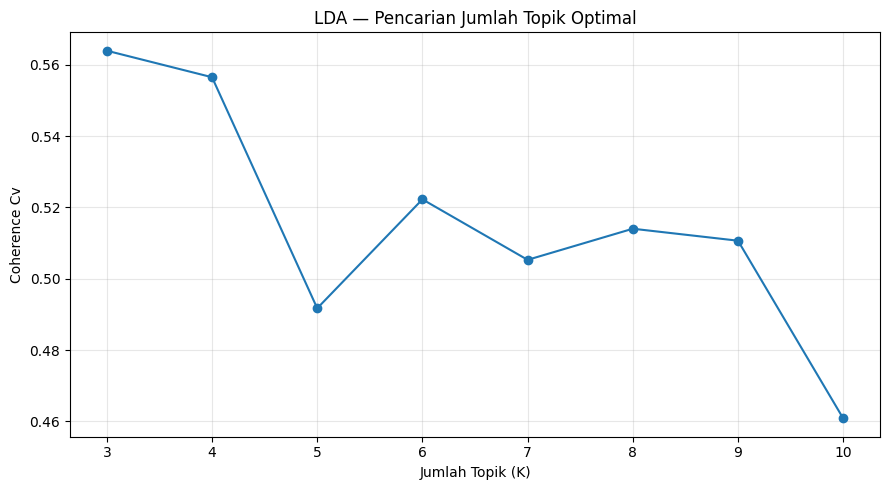

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel, Phrases
from gensim.models.phrases import Phraser

texts = data["tokens"].tolist()
bigram = Phrases(texts, min_count=5, threshold=10)
bigram_mod = Phraser(bigram)
texts_lda = [bigram_mod[doc] for doc in texts]

dictionary = corpora.Dictionary(texts_lda)
dictionary.filter_extremes(no_below=5, no_above=0.5, keep_n=100000)
corpus = [dictionary.doc2bow(doc) for doc in texts_lda]
if len(dictionary) == 0:
    raise ValueError("Vocabulary kosong. Coba kurangi no_below.")

K_VALUES = [3, 4, 5, 6, 7, 8, 9, 10]
lda_models, lda_scan_rows = {}, []
for k in K_VALUES:
    model = LdaModel(
        corpus=corpus, id2word=dictionary, num_topics=k,
        random_state=42, chunksize=2000, passes=8, iterations=100,
        alpha="symmetric", eta="auto", eval_every=None
    )
    cv = CoherenceModel(
        model=model, texts=texts_lda, dictionary=dictionary,
        coherence="c_v", processes=1
    ).get_coherence()
    lda_models[k] = model
    lda_scan_rows.append({"K": k, "coherence_cv": cv})
    print(f"K={k}: Cv={cv:.4f}")

lda_scan = pd.DataFrame(lda_scan_rows)
best_k = int(lda_scan.loc[lda_scan["coherence_cv"].idxmax(), "K"])
lda_model = lda_models[best_k]
display(lda_scan)
print("K terbaik berdasarkan Cv:", best_k)

plt.figure(figsize=(9, 5))
plt.plot(lda_scan["K"], lda_scan["coherence_cv"], marker="o")
plt.xlabel("Jumlah Topik (K)")
plt.ylabel("Coherence Cv")
plt.title("LDA — Pencarian Jumlah Topik Optimal")
plt.xticks(K_VALUES)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(WORKDIR, "fig_lda_k_scan.png"), dpi=200)
plt.show()
lda_scan.to_csv(os.path.join(WORKDIR, "lda_k_scan.csv"), index=False)

In [ ]:
lda_topics = []
print("Kata kunci 10 teratas untuk setiap topik LDA")
for topic_id in range(best_k):
    words = [w for w, weight in lda_model.show_topic(topic_id, topn=10)]
    lda_topics.append(words)
    print(f"Topik {topic_id + 1}: " + ", ".join(words))

Kata kunci 10 teratas untuk setiap topik LDA
Topik 1: people, think, god, know, said, say, like, way, time, government
Topik 2: like, know, think, time, used, use, good, game, new, problem
Topik 3: use, windows, file, software, program, files, edu, dos, using, version


## 6. Model BERTopic — Sentence Transformers + UMAP + HDBSCAN

In [ ]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN

documents = data["clean_text"].tolist()
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

umap_model = UMAP(
    n_neighbors=15, n_components=5, min_dist=0.0,
    metric="cosine", random_state=42
)
hdbscan_model = HDBSCAN(
    min_cluster_size=15, min_samples=5, metric="euclidean",
    cluster_selection_method="eom", prediction_data=True
)
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    language="english",
    calculate_probabilities=False,
    verbose=True,
    nr_topics="auto"
)
topics, probabilities = topic_model.fit_transform(documents)
topic_info = topic_model.get_topic_info()
display(topic_info.head(20))
print("Jumlah topik (tanpa outlier):", topic_info[topic_info.Topic != -1].shape[0])
print("Jumlah dokumen outlier:", int((pd.Series(topics) == -1).sum()))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (8 outputs left out)

Batches:   0%|          | 0/219 [00:00<?, ?it/s]

2026-11-13 03:10:15,342 - BERTopic - Embedding - Completed ✓
2026-11-13 03:10:15,346 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-13 03:11:11,028 - BERTopic - Dimensionality - Completed ✓
2026-11-13 03:11:11,029 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-13 03:11:11,198 - BERTopic - Cluster - Completed ✓
2026-11-13 03:11:11,200 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-11-13 03:11:12,134 - BERTopic - Representation - Completed ✓
2026-11-13 03:11:12,137 - BERTopic - Topic reduction - Reducing number of topics
2026-11-13 03:11:12,166 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-13 03:11:13,502 - BERTopic - Representation - Completed ✓
2026-11-13 03:11:13,508 - BERTopic - Topic reduction - Reduced number of topics from 89 to 22


,Topic,Count,Name,Representation,Representative_Docs
0,-1,1863,-1_the_to_of_and,"[the, to, of, and, is, that, it, in, you, for]",[noting that a particular society in this case...
1,0,2945,0_the_of_to_and,"[the, of, to, and, in, that, is, it, you, for]",[archive name jpeg faq last modified may this ...
2,1,692,1_the_game_he_to,"[the, game, he, to, in, and, was, that, of, team]",[whoa what you are effectively doing is implyi...
3,2,607,2_the_car_it_to,"[the, car, it, to, and, you, in, is, on, my]",[how to get a verbal warning for in a it s sim...
4,3,245,3_of_and_the_to,"[of, and, the, to, in, for, is, that, cancer, it]",[cut here volume number april health info com ...
5,4,207,4_the_of_to_space,"[the, of, to, space, and, in, be, it, that, for]",[ken your arguments are thoughtful but you are...
6,5,65,5_printer_print_hp_deskjet,"[printer, print, hp, deskjet, the, paper, lase...",[just thought i would add to deskjet thread i ...
7,6,51,6_ear_wax_it_to,"[ear, wax, it, to, and, the, you, hearing, is,...",[question what s your experience with car wash...
8,7,38,7_fonts_font_keymap_string,"[fonts, font, keymap, string, my, dpi, to, win...",[try to run xsun under truss the best way to d...
9,8,28,8_radar_detector_ka_detectors,"[radar, detector, ka, detectors, valentine, th...",[i ve had a valentine for about months now and...


Jumlah topik (tanpa outlier): 21
Jumlah dokumen outlier: 1863


## 7. Visualisasi BERTopic dan ekspor HTML

In [ ]:
# Simpan visualisasi interaktif sebagai HTML agar dapat dibuka di browser.
fig_bar = topic_model.visualize_barchart(top_n_topics=15)
fig_bar.write_html(os.path.join(WORKDIR, "bertopic_barchart_auto.html"))

fig_distance = topic_model.visualize_topics()
fig_distance.write_html(os.path.join(WORKDIR, "bertopic_intertopic_distance_auto.html"))

fig_hierarchy = topic_model.visualize_hierarchy()
fig_hierarchy.write_html(os.path.join(WORKDIR, "bertopic_hierarchy_auto.html"))

print("Tiga visualisasi HTML berhasil disimpan.")

Tiga visualisasi HTML berhasil disimpan.


### 7A. Tampilkan gambar visualisasi langsung di notebook

Bagian ini menampilkan visualisasi BERTopic di bawah cell, sehingga hasil analisis dapat langsung dilihat tanpa membuka file HTML. Selain itu, setiap visualisasi diekspor menjadi PNG untuk dimasukkan ke laporan.

In [ ]:
from IPython.display import display

print("1) BERTopic — Topic Word Scores / Barchart")
display(fig_bar)

print("2) BERTopic — Hierarchical Clustering")
display(fig_hierarchy)

print("3) BERTopic — Intertopic Distance Map")
display(fig_distance)

# Simpan juga versi gambar PNG untuk laporan.
# Memerlukan paket kaleido yang sudah dipasang pada tahap instalasi.
png_exports = {
    "bertopic_barchart_auto.png": fig_bar,
    "bertopic_hierarchy_auto.png": fig_hierarchy,
    "bertopic_intertopic_distance_auto.png": fig_distance,
}

for filename, figure in png_exports.items():
    try:
        figure.write_image(os.path.join(WORKDIR, filename), width=1400, height=900, scale=2)
        print("PNG tersimpan:", filename)
    except Exception as e:
        print(f"PNG {filename} belum dapat dibuat: {e}")
        print("File HTML interaktif tetap tersedia untuk visualisasi ini.")

1) BERTopic — Topic Word Scores / Barchart


2) BERTopic — Hierarchical Clustering


3) BERTopic — Intertopic Distance Map


PNG bertopic_barchart_auto.png belum dapat dibuat: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

File HTML interaktif tetap tersedia untuk visualisasi ini.
PNG bertopic_hierarchy_auto.png belum dapat dibuat: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

File HTML interaktif tetap tersedia untuk visualisasi ini.
PNG bertopic_intertopic_distance_auto.png belum dapat dibuat: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

File HTML interaktif tetap tersedia untuk visualisasi ini.


## 8. Evaluasi Coherence Cv LDA vs BERTopic

,model,coherence_cv,jumlah_topik,jumlah_outlier
0,LDA,0.589551,3,0
1,BERTopic,0.673528,21,1863


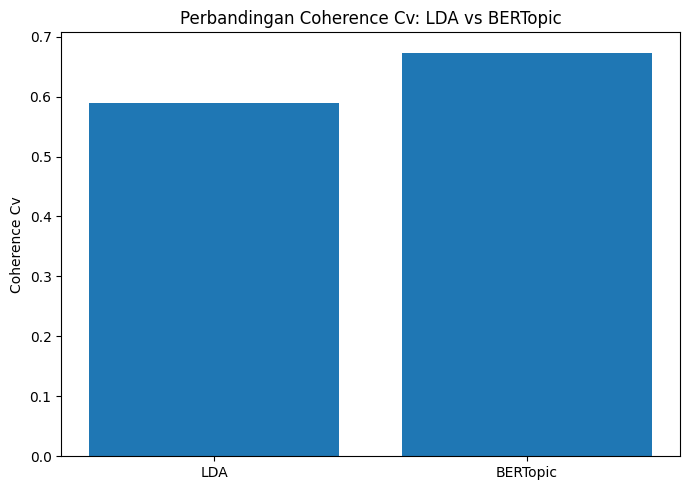

In [ ]:
# Coherence BERTopic dihitung dari 10 kata teratas per topik.
# Kata yang tidak ada dalam dictionary evaluasi diabaikan agar kedua model
# dinilai menggunakan vocabulary corpus yang sama.
vocab = set(dictionary.token2id.keys())
bertopic_topics, bertopic_topic_ids = [], []
for tid in topic_model.get_topics().keys():
    if tid == -1:
        continue
    words = [w for w, score in topic_model.get_topic(tid)[:10]]
    bertopic_topic_ids.append(tid)
    bertopic_topics.append(words)

bertopic_topics_cv = [[w for w in words if w in vocab][:10] for words in bertopic_topics]
bertopic_topics_cv = [t for t in bertopic_topics_cv if len(t) >= 2]

lda_cv = CoherenceModel(
    topics=lda_topics, texts=texts_lda, dictionary=dictionary,
    coherence="c_v", processes=1
).get_coherence()

bertopic_cv = (
    CoherenceModel(
        topics=bertopic_topics_cv, texts=texts_lda, dictionary=dictionary,
        coherence="c_v", processes=1
    ).get_coherence()
    if bertopic_topics_cv else np.nan
)

evaluation = pd.DataFrame([
    {"model": "LDA", "coherence_cv": lda_cv, "jumlah_topik": best_k,
     "jumlah_outlier": 0},
    {"model": "BERTopic", "coherence_cv": bertopic_cv,
     "jumlah_topik": len(bertopic_topics),
     "jumlah_outlier": int((pd.Series(topics) == -1).sum())}
])
display(evaluation)

plt.figure(figsize=(7, 5))
plt.bar(evaluation["model"], evaluation["coherence_cv"])
plt.ylabel("Coherence Cv")
plt.title("Perbandingan Coherence Cv: LDA vs BERTopic")
plt.tight_layout()
plt.savefig(os.path.join(WORKDIR, "fig_perbandingan_cv.png"), dpi=200)
plt.show()
evaluation.to_csv(os.path.join(WORKDIR, "hasil_evaluasi.csv"), index=False)

## 9. Analisis sensitivitas parameter BERTopic

In [ ]:
# Uji beberapa nilai min_cluster_size. Setiap pengujian menggunakan embedding
# dokumen yang sama agar waktu komputasi lebih efisien.
from sklearn.metrics import silhouette_score
from hdbscan import HDBSCAN

embeddings = embedding_model.encode(
    documents, show_progress_bar=True, batch_size=64
)
reduced_embeddings = umap_model.fit_transform(embeddings)

sensitivity_rows = []
for mcs in [10, 15, 20, 30]:
    clusterer = HDBSCAN(
        min_cluster_size=mcs, min_samples=5, metric="euclidean",
        cluster_selection_method="eom", prediction_data=False
    )
    labels = clusterer.fit_predict(reduced_embeddings)
    n_topics = len(set(labels)) - (1 if -1 in labels else 0)
    outliers = int((labels == -1).sum())
    valid = labels != -1
    sil = np.nan
    if valid.sum() > 2 and len(set(labels[valid])) > 1:
        sil = silhouette_score(reduced_embeddings[valid], labels[valid])
    sensitivity_rows.append({
        "min_cluster_size": mcs,
        "jumlah_topik": n_topics,
        "jumlah_outlier": outliers,
        "persentase_outlier": 100 * outliers / len(labels),
        "silhouette_non_outlier": sil
    })
    print(sensitivity_rows[-1])

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df)
sensitivity_df.to_csv(
    os.path.join(WORKDIR, "sensitivitas_min_cluster_size.csv"), index=False
)

Batches:   0%|          | 0/110 [00:00<?, ?it/s]

{'min_cluster_size': 10, 'jumlah_topik': 144, 'jumlah_outlier': 2181, 'persentase_outlier': 31.25537403267412, 'silhouette_non_outlier': np.float32(0.5123145)}
{'min_cluster_size': 15, 'jumlah_topik': 86, 'jumlah_outlier': 1626, 'persentase_outlier': 23.301805674978503, 'silhouette_non_outlier': np.float32(0.54553235)}
{'min_cluster_size': 20, 'jumlah_topik': 65, 'jumlah_outlier': 1561, 'persentase_outlier': 22.37030667813127, 'silhouette_non_outlier': np.float32(0.5175209)}
{'min_cluster_size': 30, 'jumlah_topik': 42, 'jumlah_outlier': 1519, 'persentase_outlier': 21.76841501862998, 'silhouette_non_outlier': np.float32(0.5978094)}


,min_cluster_size,jumlah_topik,jumlah_outlier,persentase_outlier,silhouette_non_outlier
0,10,144,2181,31.255374,0.512314
1,15,86,1626,23.301806,0.545532
2,20,65,1561,22.370307,0.517521
3,30,42,1519,21.768415,0.597809


## 10. Uji kestabilan seed LDA

In [ ]:
# Menguji apakah pola coherence LDA relatif stabil untuk random seed berbeda.
# Untuk menjaga waktu eksekusi, uji K terbaik saja pada beberapa seed.
seed_rows = []
for seed in [11, 21, 42, 77, 123]:
    model_seed = LdaModel(
        corpus=corpus, id2word=dictionary, num_topics=best_k,
        random_state=seed, chunksize=2000, passes=6, iterations=100,
        alpha="symmetric", eta="auto", eval_every=None
    )
    cv_seed = CoherenceModel(
        model=model_seed, texts=texts_lda, dictionary=dictionary,
        coherence="c_v", processes=1
    ).get_coherence()
    seed_rows.append({"seed": seed, "K": best_k, "coherence_cv": cv_seed})
    print(f"seed={seed}: Cv={cv_seed:.4f}")

seed_df = pd.DataFrame(seed_rows)
display(seed_df)
seed_df.to_csv(os.path.join(WORKDIR, "kestabilan_seed.csv"), index=False)

seed=11: Cv=0.5301
seed=21: Cv=0.4935
seed=42: Cv=0.5837
seed=77: Cv=0.5053
seed=123: Cv=0.5201


,seed,K,coherence_cv
0,11,3,0.530056
1,21,3,0.493452
2,42,3,0.583700
3,77,3,0.505306
4,123,3,0.520141


## 11. Dokumen representatif dan interpretasi topik

In [ ]:
for tid in bertopic_topic_ids[:10]:
    print(f"\\n===== BERTopic {tid} =====")
    print("Kata kunci:", ", ".join([w for w, _ in topic_model.get_topic(tid)[:10]]))
    for j, doc in enumerate((topic_model.get_representative_docs(tid) or [])[:2], 1):
        print(f"{j}. {doc[:400]}...")

\n===== BERTopic 0 =====
Kata kunci: the, of, to, and, in, that, is, it, you, for
1. archive name jpeg faq last modified may this faq article discusses jpeg image compression suggestions for additions and clarifications are welcome new since version of may added info on imageviewer for next this article includes the following sections what is jpeg why use jpeg when should i use jpeg and when should i stick with gif how well does jpeg compress images what are good quality settings ...
2. accounts of anti armenian human right violations in azerbaijan prelude to current events in nagorno karabakh they beat up the husband dragged the wife outside and stood her naked next to our burning things her husband was lying at her feet on the ground the crowd shouted look at the naked armenian they were going to throw the poor woman into the fire mamma wouldn t allow it but i went to the windo...
\n===== BERTopic 1 =====
Kata kunci: the, game, he, to, in, and, was, that, of, team
1. whoa what you ar

## 12. Ekspor semua hasil (CSV, PNG, HTML) dan unduh sebagai ZIP

In [ ]:
# Salin dataset sumber ke folder output dan simpan tabel ringkasan topik.
shutil.copy2(csv_path, os.path.join(WORKDIR, "dataset_yang_dianalisis.csv"))
topic_info.to_csv(os.path.join(WORKDIR, "ringkasan_topik_bertopic.csv"), index=False)

# Simpan kata kunci topik LDA dan BERTopic ke CSV.
topic_rows = []
for i, words in enumerate(lda_topics):
    topic_rows.append({"model": "LDA", "topic_id": i, "keywords": ", ".join(words)})
for tid, words in zip(bertopic_topic_ids, bertopic_topics):
    topic_rows.append({"model": "BERTopic", "topic_id": tid, "keywords": ", ".join(words)})
pd.DataFrame(topic_rows).to_csv(
    os.path.join(WORKDIR, "kata_kunci_topik.csv"), index=False
)

zip_path = "/content/hasil_Tugas2_LDA_vs_BERTopic.zip"
shutil.make_archive(zip_path[:-4], "zip", WORKDIR)
print("Paket hasil:", zip_path)
files.download(zip_path)

Paket hasil: /content/hasil_Tugas2_LDA_vs_BERTopic.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Panduan kesimpulan akademik

Gunakan hasil aktual dari `hasil_evaluasi.csv`:
- Model dengan nilai Coherence Cv lebih tinggi memiliki keterkaitan semantik kata kunci yang lebih baik menurut metrik Cv pada corpus ini.
- LDA menggunakan representasi bag-of-words dan jumlah topik K yang ditentukan melalui eksperimen.
- BERTopic memanfaatkan embedding kalimat dan clustering sehingga dapat menangkap kemiripan semantik yang lebih kontekstual.
- Periksa kata kunci dan dokumen representatif. Nilai Cv saja tidak cukup untuk menyimpulkan interpretabilitas manusia.
- Laporkan pula jumlah topik, jumlah/persentase outlier BERTopic, sensitivitas parameter, dan kestabilan seed.